In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [3]:
def Tanh(x):
    return torch.tanh(torch.as_tensor(x, dtype=torch.float32)).numpy()

In [4]:
def logistic_sigmoid(x):
    return(1/(1+np.exp(-x)))

In [13]:
def ReLu(x):
    return(np.maximum(0,x))

In [5]:
def GeLU(x):
    return F.gelu(torch.as_tensor(x, dtype=torch.float32)).numpy()

In [6]:
def Swish(x):
    return F.silu(torch.as_tensor(x, dtype=torch.float32)).numpy()

In [7]:
def SeLu(x):
    return F.selu(torch.as_tensor(x, dtype=torch.float32)).numpy()

In [8]:
def HardSigmoid(x):
    return F.hardsigmoid(torch.as_tensor(x, dtype=torch.float32)).numpy()

In [9]:
x = np.linspace(-4,4,100)
nx = np.linspace(-4,0,3)

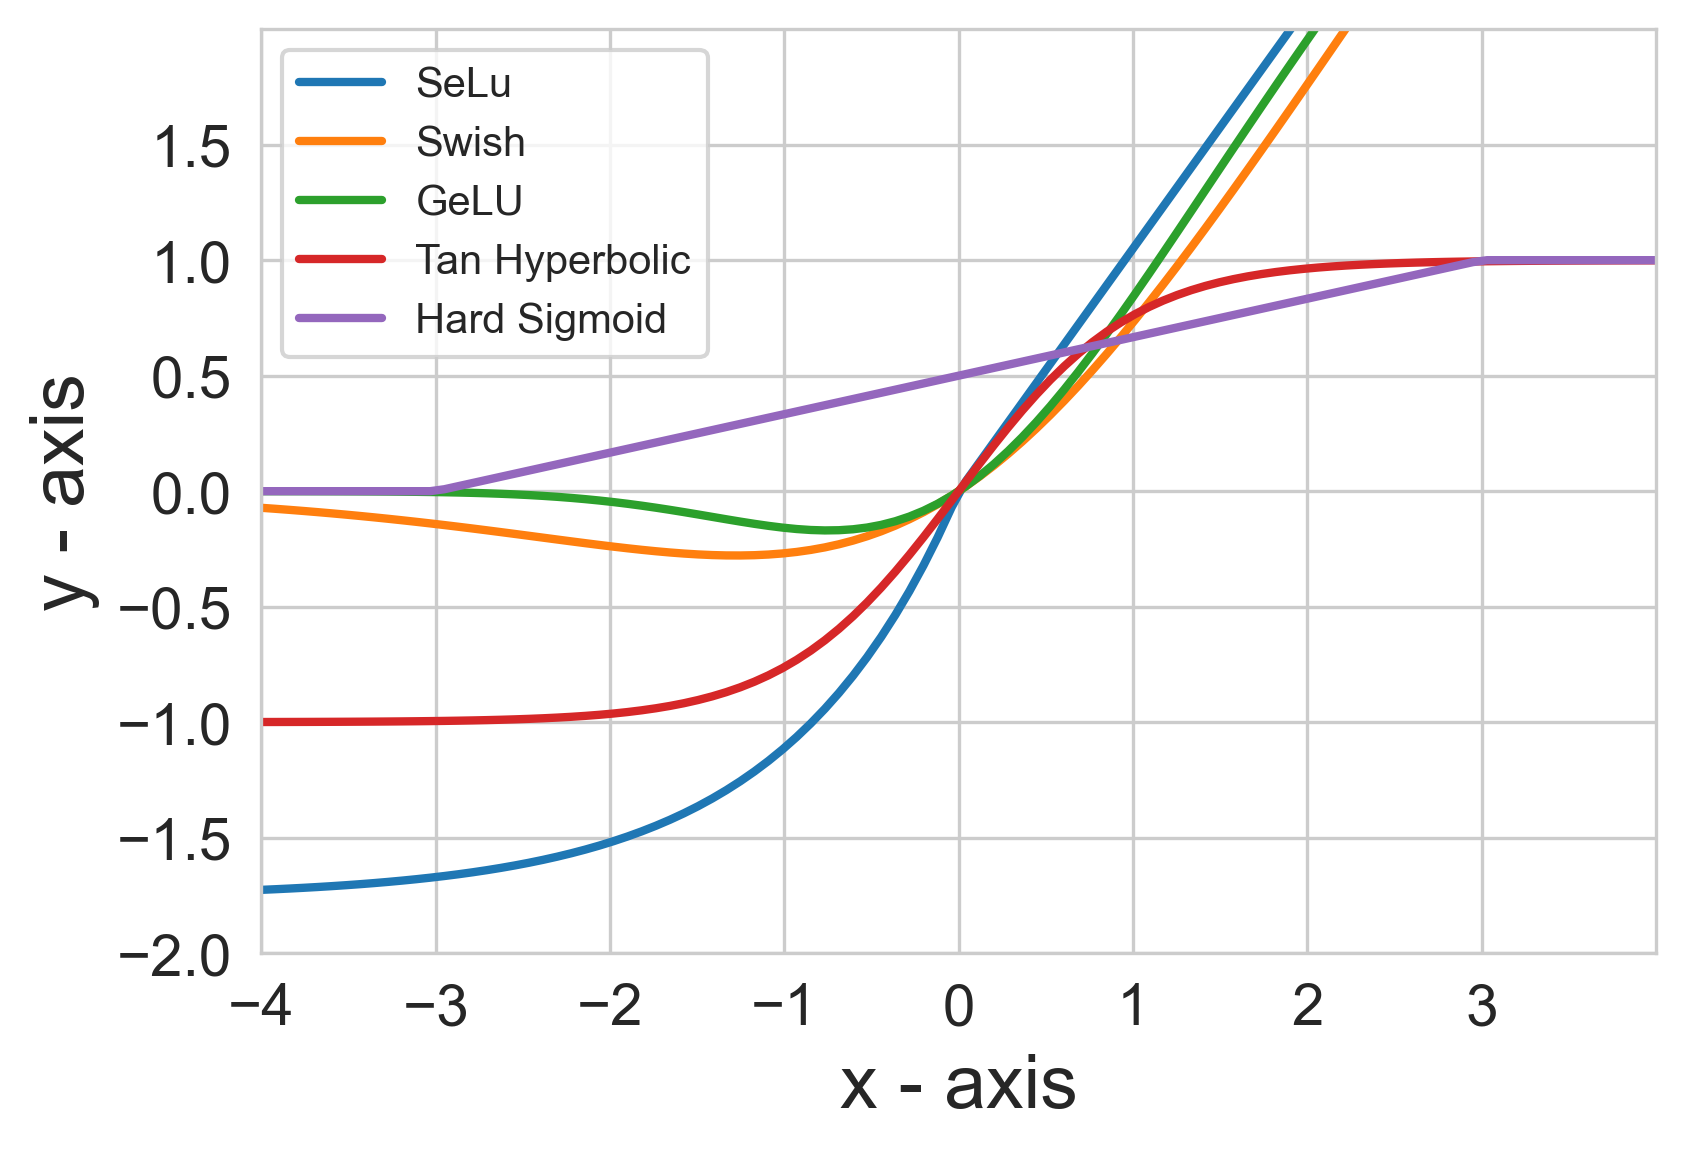

In [10]:
plt.figure(figsize=(6,4))
plt.plot(x,SeLu(x),lw=2,label='SeLu')
plt.plot(x,Swish(x),lw=2,label='Swish')
plt.plot(x,GeLU(x),lw=2,label='GeLU')
plt.plot(x,Tanh(x),lw=2,label='Tan Hyperbolic')
plt.plot(x,HardSigmoid(x),lw=2,label='Hard Sigmoid')
plt.xlabel('x - axis',fontsize=18)
plt.ylabel('y - axis',fontsize=18)
plt.xticks(np.arange(-4, 4, 1),fontsize=14)
plt.yticks(np.arange(-2, 2, 0.5),fontsize=14)
plt.axis([-4,4,-2,2])
plt.legend()
plt.savefig('fig1.png', dpi=300, format='png', bbox_inches='tight')
plt.show()

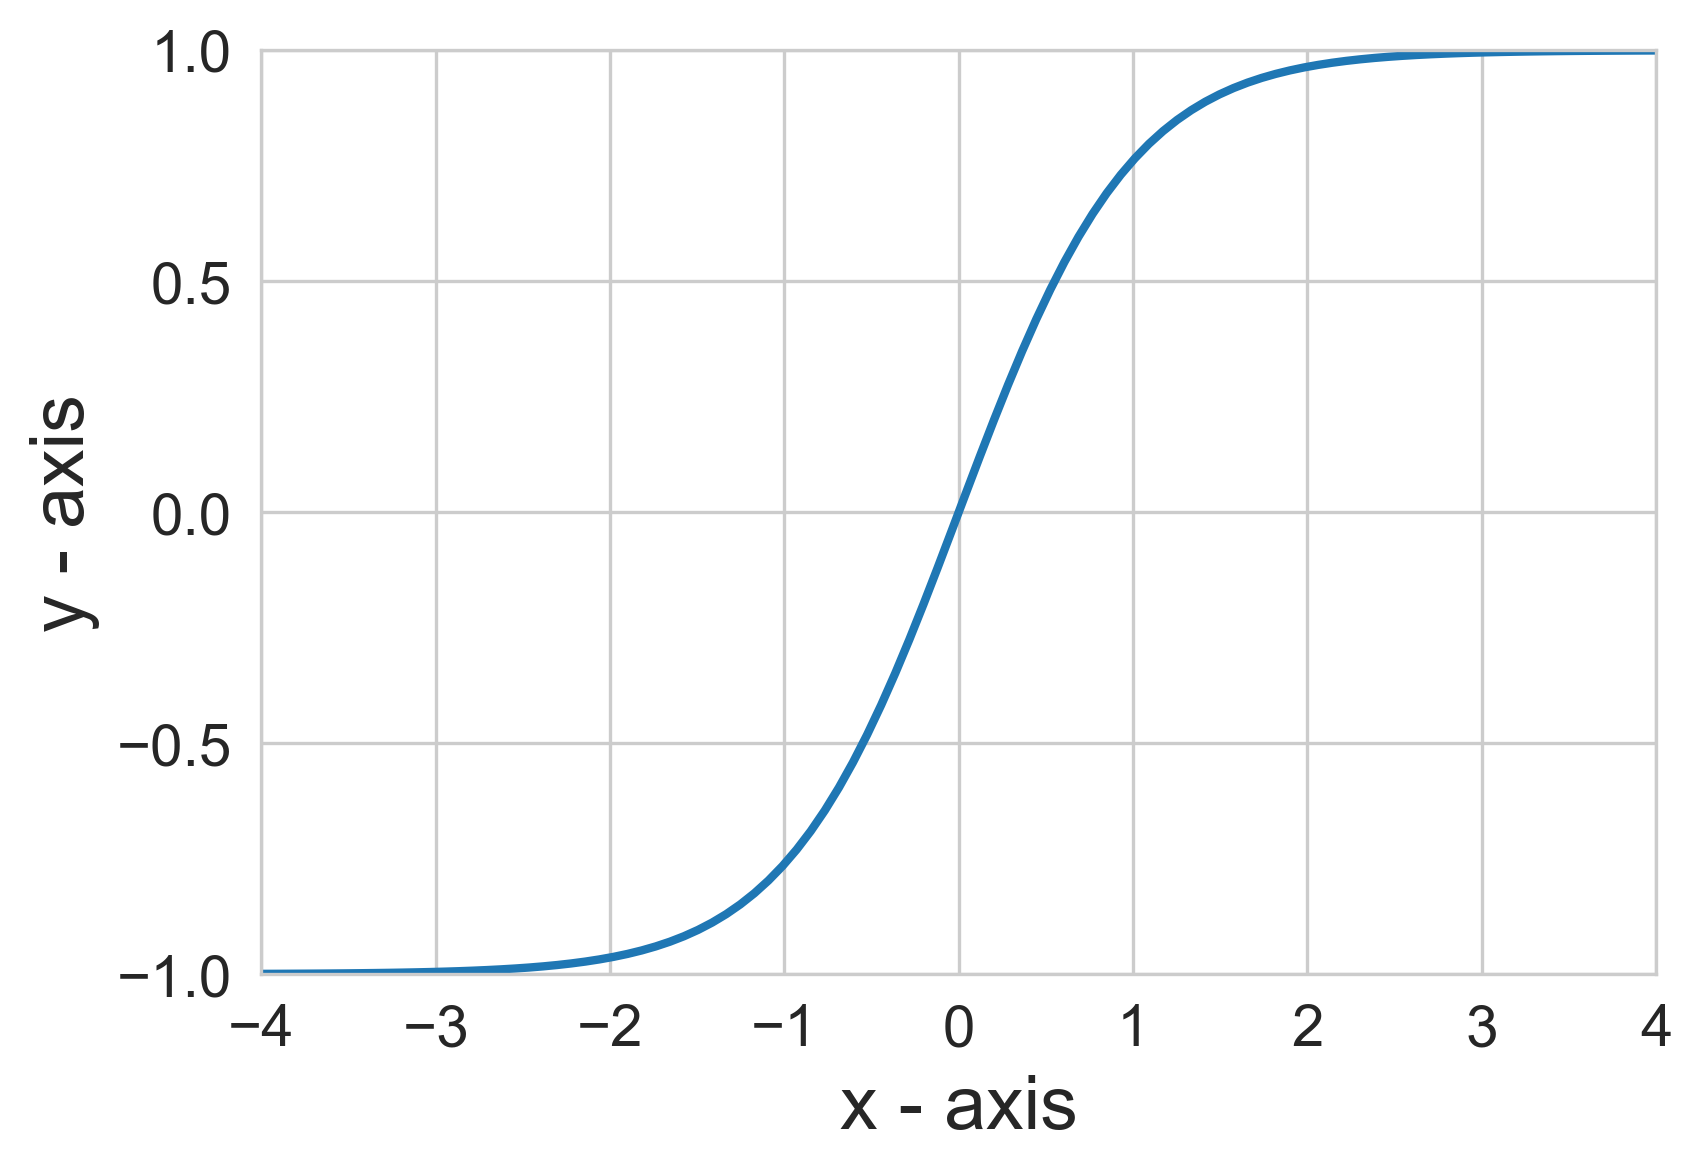

In [11]:
plt.figure(figsize=(6,4))
plt.plot(x,np.tanh(x),lw=2)
plt.xlabel('x - axis',fontsize=18)
plt.ylabel('y - axis',fontsize=18)
plt.xticks(np.arange(-4, 5, 1),fontsize=14)
plt.yticks(np.arange(-1, 2, 0.5),fontsize=14)
plt.axis([-4,4,-1,1])
plt.savefig('fig2.png', dpi=300, format='png', bbox_inches='tight')
plt.show()

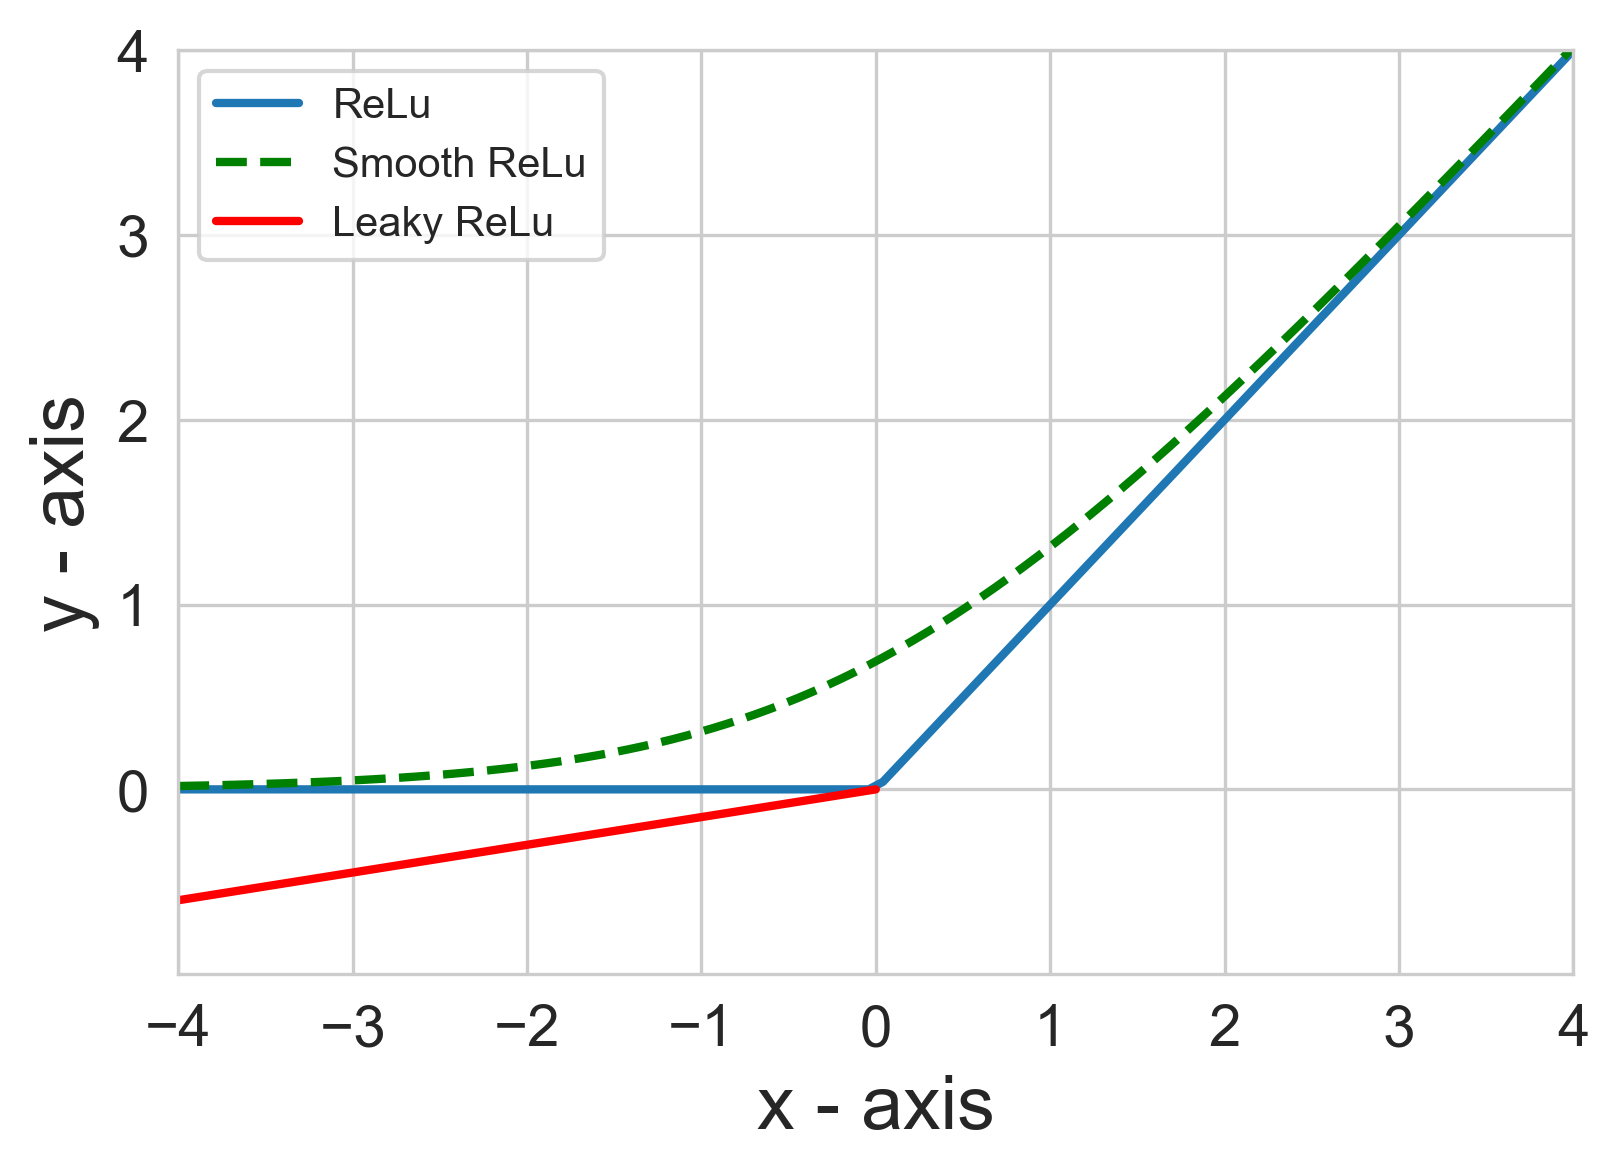

In [14]:
plt.figure(figsize=(6,4))
plt.plot(x,ReLu(x),lw=2,label='ReLu')
plt.plot(x,np.log(1+np.exp(x)),'--',lw=2,color='green',label='Smooth ReLu')
plt.plot(nx,0.15*nx,lw=2,color='red',label='Leaky ReLu')
plt.xlabel('x - axis',fontsize=18)
plt.ylabel('y - axis',fontsize=18)
plt.xticks(np.arange(-4, 5, 1),fontsize=14)
plt.yticks(np.arange(0, 5, 1),fontsize=14)
plt.axis([-4,4,-1,4])
plt.legend(loc='upper left')
plt.savefig('fig3.png', dpi=300, format='png', bbox_inches='tight')
plt.show()

In [16]:
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.sigmoid(x)
# Compute the derivative at each input using automatic differentiation.
gradient = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y))[0]

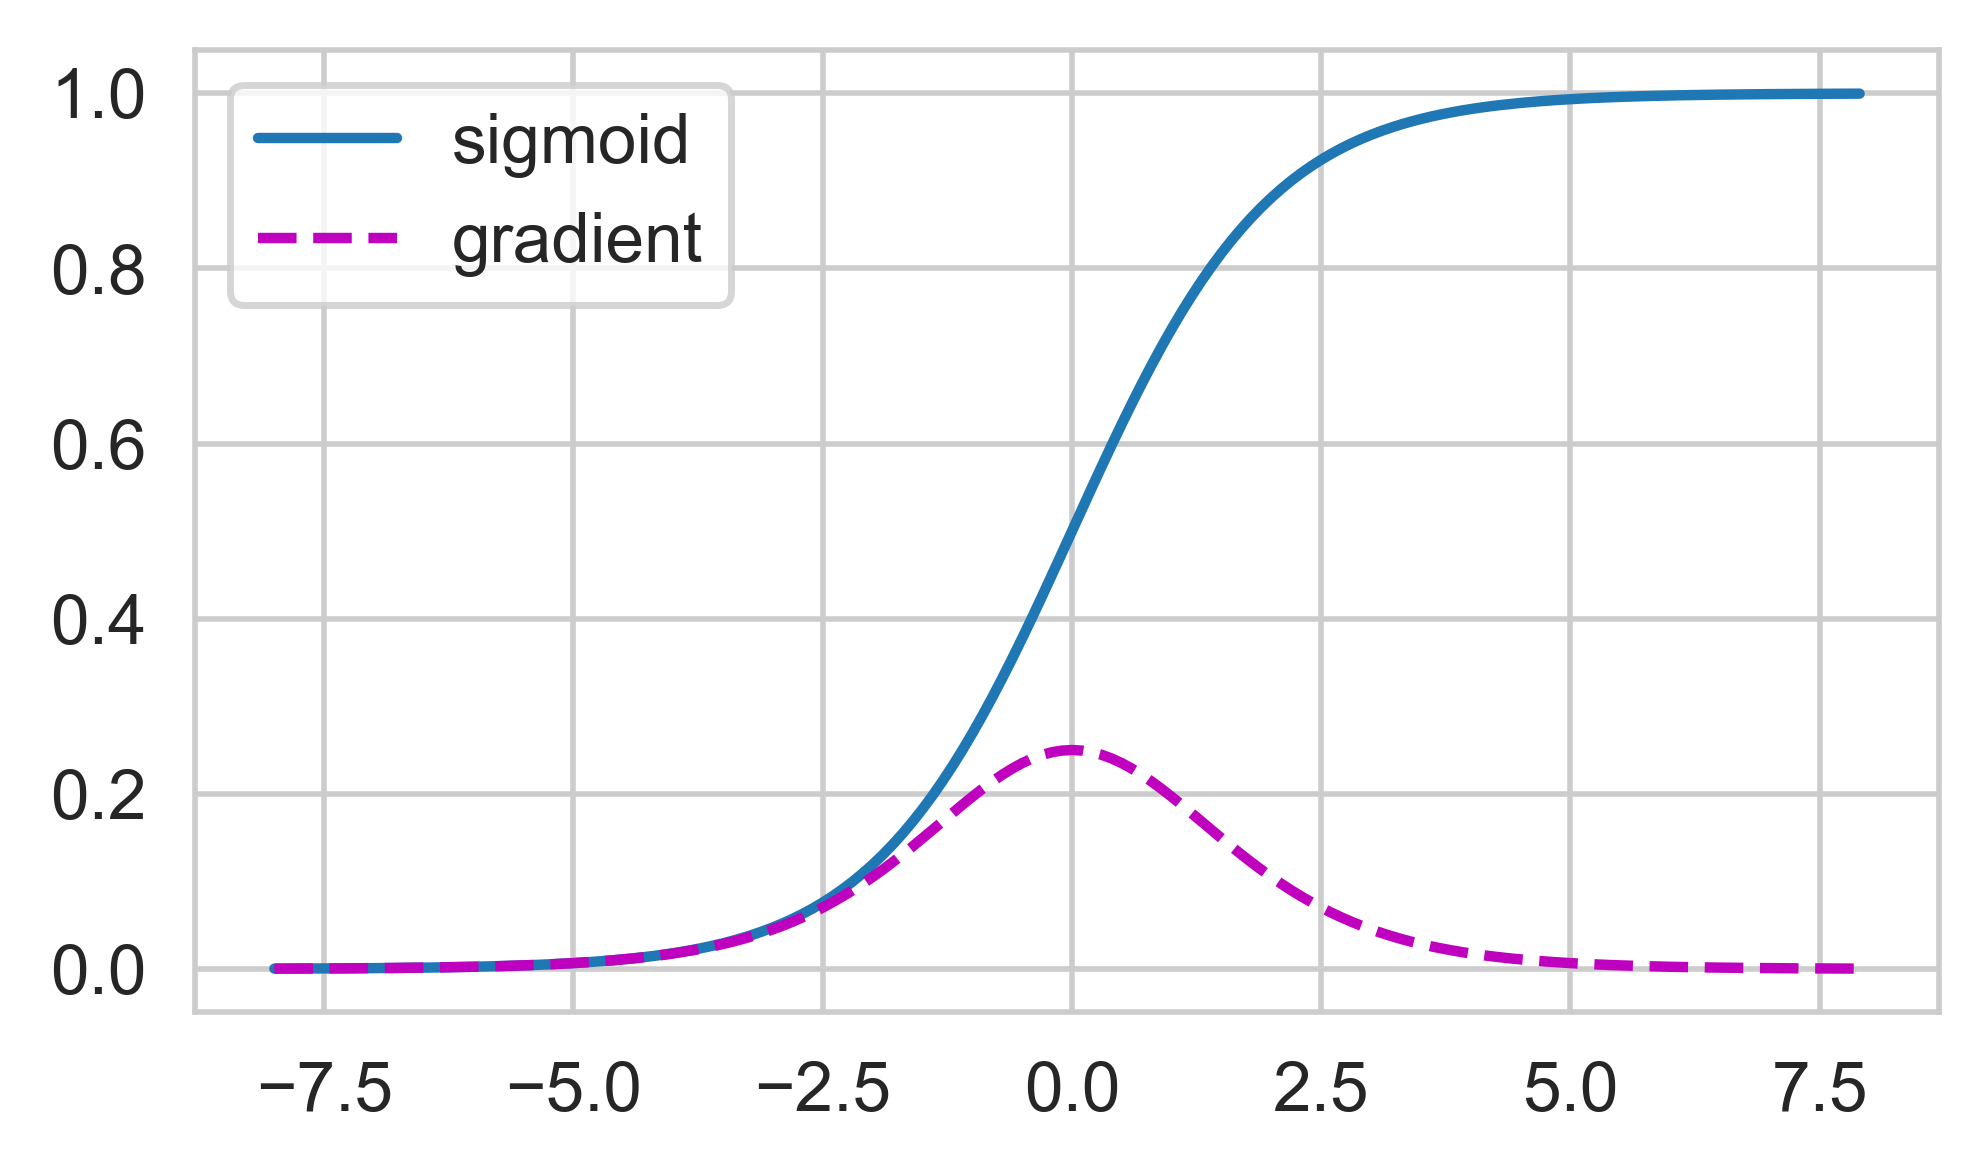

In [18]:
plt.figure(figsize=(4.5,2.5),dpi=250)
plt.plot(x.detach().numpy(), y.detach().numpy())
plt.plot(x.detach().numpy(), gradient.detach().numpy(),'--',color='m')
plt.grid('on')
plt.legend(['sigmoid','gradient'])
plt.show()